In [20]:
pip install pandas scipy numpy


Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np
import pandas as pd
from scipy.io import loadmat

data = loadmat("./SeversonBattery.mat")

print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'Cycles_Flt', 'Features_mov_Flt', 'Num_Cycles_Flt', 'PCL_Flt', 'RUL_Flt', 'secondary_test_ind', 'test_ind', 'train_ind'])


In [12]:
features = data["Features_mov_Flt"]
rul = data["RUL_Flt"].flatten()
pcl = data["PCL_Flt"].flatten()
cycles = data["Cycles_Flt"].flatten()

print(features.shape)
print(rul.shape)
print(pcl.shape)
print(cycles.shape)
print(f"Features shape: {features.shape}")
print(f"RUL shape:      {rul.shape}")
print(f"PCL shape:      {pcl.shape}")
print(f"Cycles shape:   {cycles.shape}")

(99281, 8)
(99281,)
(99281,)
(99281,)
Features shape: (99281, 8)
RUL shape:      (99281,)
PCL shape:      (99281,)
Cycles shape:   (99281,)


In [21]:
inputs = np.hstack((features, cycles[:, None]))
soh = 1 - pcl
print(inputs)

[[ 1.01377922e-02  1.02366675e-02  3.18750108e+01 ... -6.68380971e+00
   3.50992778e+00  2.00000000e+00]
 [ 1.01184425e-02  1.01855037e-02  3.19032506e+01 ... -6.72043974e+00
   3.52377085e+00  3.00000000e+00]
 [ 1.00655531e-02  1.01072170e-02  3.19130349e+01 ... -6.72412358e+00
   3.50912933e+00  4.00000000e+00]
 ...
 [ 7.77588485e-03  1.40351629e-02  3.26656016e+01 ... -4.44226799e+00
   1.72779795e+00  1.79800000e+03]
 [ 7.78554352e-03  1.40635394e-02  3.27185230e+01 ... -4.42726286e+00
   1.72404377e+00  1.79900000e+03]
 [ 7.76053270e-03  1.40601889e-02  3.26668491e+01 ... -4.43801448e+00
   1.72071973e+00  1.80000000e+03]]


In [13]:
num_cycles = data["Num_Cycles_Flt"].flatten().astype(int)

print("Number of batteries:", len(num_cycles))
print("Total cycles:", num_cycles.sum())

Number of batteries: 124
Total cycles: 99281


In [14]:
batteries = []

start = 0

for i, n in enumerate(num_cycles):
    end = start + n
    
    battery = {
        "id": i + 1,
        "features": features[start:end],
        "cycle": cycles[start:end],
        "pcl": pcl[start:end],
        "rul": rul[start:end]
    }
    
    battery["soh"] = 1 - battery["pcl"]
    
    batteries.append(battery)
    start = end

print("Batteries reconstructed:", len(batteries))

Batteries reconstructed: 124


In [44]:
print("Number of batteries:", len(num_cycles))
print("Total cycle records:", num_cycles.sum())
print("Number of features:", features.shape[1])

Number of batteries: 124
Total cycle records: 99281
Number of features: 8


In [16]:
pip install matplotlib

  Using cached matplotlib-3.11.1-cp313-cp313-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.63.0-cp313-cp313-macosx_10_13_universal2.whl.metadata (118 kB)
  Using cached kiwisolver-1.5.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (5.1 kB)
  Using cached pillow-12.3.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.11.1-cp313-cp313-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.3.3-cp313-cp313-macosx_11_0_arm64.whl (274 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.63.0-cp313-cp313-macosx_10_13_universal2.whl (2.9 MB)
Using cached kiwisolver-1.5.0-cp313-cp313-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-12.3.0-cp313-cp313-macosx_11_0_arm64.whl (4.8 MB)
Using cached pyparsing-3.3.2

In [45]:
# this is the dataset 
import pandas as pd

feature_names = [
    "Slope",
    "Intercept",
    "Avg_Temperature",
    "Internal_Resistance",
    "Charge_Time",
    "dQdV_max",
    "dQdV_min",
    "dQdV_var"
]

df = pd.DataFrame(features, columns=feature_names)

df["Cycle"] = cycles
df["SoH"] = soh
df["RUL"] = data["RUL_Flt"].flatten()

df.head(10)

,Slope,Intercept,Avg_Temperature,Internal_Resistance,Charge_Time,dQdV_max,dQdV_min,dQdV_var,Cycle,SoH,RUL
0,0.010138,0.010237,31.875011,0.016742,13.341250,-0.145350,-6.683810,3.509928,2,0.973354,1850
1,0.010118,0.010186,31.903251,0.016733,13.383513,-0.116941,-6.720440,3.523771,3,0.974455,1849
2,0.010066,0.010107,31.913035,0.016716,13.397398,-0.123170,-6.724124,3.509129,4,0.975009,1848
3,0.010056,0.010079,31.924607,0.016702,13.383409,-0.126216,-6.724090,3.514826,5,0.975613,1847
4,0.010038,0.010043,31.931898,0.016687,13.374894,-0.117784,-6.746651,3.515412,6,0.975978,1846
5,0.010040,0.010035,31.926675,0.016672,13.369111,-0.120433,-6.711175,3.510442,7,0.976356,1845
6,0.010040,0.010027,31.925960,0.016659,13.377159,-0.123851,-6.702896,3.507812,8,0.976704,1844
7,0.010033,0.010015,31.918975,0.016650,13.383163,-0.125641,-6.693088,3.503736,9,0.976811,1843
8,0.010026,0.010004,31.910317,0.016641,13.387881,-0.126699,-6.682956,3.499039,10,0.976852,1842
9,0.010018,0.009988,31.900423,0.016633,13.383193,-0.127645,-6.683488,3.497239,11,0.977074,1841


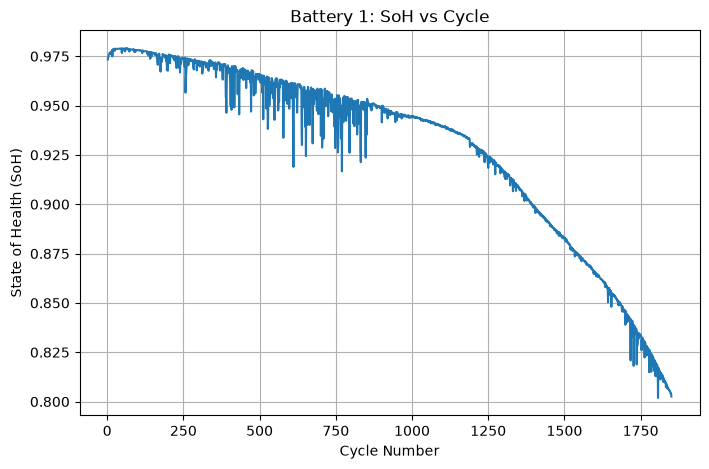

In [47]:
import matplotlib.pyplot as plt

battery = batteries[0]

plt.figure(figsize=(8, 5))
plt.plot(battery["cycle"], battery["soh"])
plt.xlabel("Cycle Number")
plt.ylabel("State of Health (SoH)")
plt.title("Battery 1: SoH vs Cycle")
plt.grid(True)
plt.show()

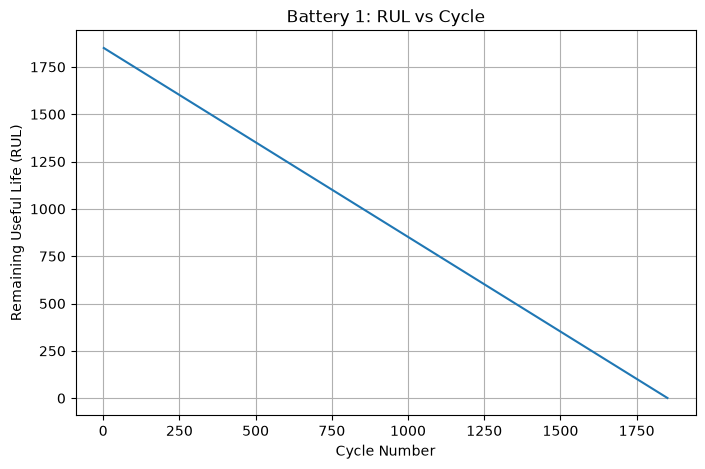

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(battery["cycle"], battery["rul"])
plt.xlabel("Cycle Number")
plt.ylabel("Remaining Useful Life (RUL)")
plt.title("Battery 1: RUL vs Cycle")
plt.grid(True)
plt.show()

In [22]:
X = np.hstack((features, cycles[:, None]))
y = soh

In [26]:
pip install scikit-learn


  Using cached scikit_learn-1.9.0-cp313-cp313-macosx_12_0_arm64.whl.metadata (11 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached narwhals-2.25.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
Using cached scikit_learn-1.9.0-cp313-cp313-macosx_12_0_arm64.whl (8.2 MB)
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
Using cached narwhals-2.25.0-py3-none-any.whl (467 kB)
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [29]:
print("Train indices shape:", data["train_ind"].shape)
print("Test indices shape:", data["test_ind"].shape)
print("Secondary test shape:", data["secondary_test_ind"].shape)

print("Train indices:")
print(data["train_ind"])

print("Test indices:")
print(data["test_ind"])

print("Secondary test indices:")
print(data["secondary_test_ind"])

Train indices shape: (1, 41)
Test indices shape: (1, 43)
Secondary test shape: (1, 40)
Train indices:
[[ 2  4  6  8 10 12 14 16 18 20 22 24 26 28 30 32 34 36 38 40 42 44 46 48
  50 52 54 56 58 60 62 64 66 68 70 72 74 76 78 80 82]]
Test indices:
[[ 1  3  5  7  9 11 13 15 17 19 21 23 25 27 29 31 33 35 37 39 41 43 45 47
  49 51 53 55 57 59 61 63 65 67 69 71 73 75 77 79 81 83 84]]
Secondary test indices:
[[ 85  86  87  88  89  90  91  92  93  94  95  96  97  98  99 100 101 102
  103 104 105 106 107 108 109 110 111 112 113 114 115 116 117 118 119 120
  121 122 123 124]]


In [30]:
# Get battery-level indices from the processed dataset

train_batteries = data["train_ind"].flatten() - 1
val_batteries = data["test_ind"].flatten() - 1
test_batteries = data["secondary_test_ind"].flatten() - 1

print("Training batteries:", len(train_batteries))
print("Validation batteries:", len(val_batteries))
print("Test batteries:", len(test_batteries))

Training batteries: 41
Validation batteries: 43
Test batteries: 40


In [31]:
num_cycles = data["Num_Cycles_Flt"].flatten().astype(int)

print("Number of batteries:", len(num_cycles))
print("Total cycle records:", num_cycles.sum())

Number of batteries: 124
Total cycle records: 99281


In [32]:
# Reconstruct the cycle ranges belonging to each battery

battery_ranges = []

start = 0

for n in num_cycles:
    end = start + n
    battery_ranges.append((start, end))
    start = end

print("Number of battery ranges:", len(battery_ranges))
print("First 5 ranges:", battery_ranges[:5])

Number of battery ranges: 124
First 5 ranges: [(0, np.int64(1850)), (np.int64(1850), np.int64(4008)), (np.int64(4008), np.int64(6243)), (np.int64(6243), np.int64(7675)), (np.int64(7675), np.int64(9382))]


In [33]:
# Convert battery-level indices into cycle-level data

def build_dataset(battery_indices):
    X_parts = []
    y_parts = []

    for battery_idx in battery_indices:
        start, end = battery_ranges[battery_idx]

        X_parts.append(X[start:end])
        y_parts.append(y[start:end])

    X_combined = np.vstack(X_parts)
    y_combined = np.concatenate(y_parts)

    return X_combined, y_combined


# Build the three datasets
X_train, y_train = build_dataset(train_batteries)
X_val, y_val = build_dataset(val_batteries)
X_test, y_test = build_dataset(test_batteries)


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27584, 9)
y_train: (27584,)
X_val: (30457, 9)
y_val: (30457,)
X_test: (41240, 9)
y_test: (41240,)


In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [37]:
pip install torch

  Using cached torch-2.13.0-cp313-cp313-macosx_14_0_arm64.whl.metadata (39 kB)
  Using cached filelock-3.32.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
Using cached torch-2.13.0-cp313-cp313-macosx_14_0_arm64.whl (111.2 MB)
Using cached fsspec-2026.7.0-py3-none-any.whl (206 kB)
Using cached networkx-3.6.1-py3-none-any.whl (2.1 MB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
Using cached filelock-3.32.4-py3-none-any.whl (99 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [torch]━━━━━ 5/6 [torch]]x]mpy]
Note: you may need to restart the kernel to use updated packages.


In [38]:
import torch
import torch.nn as nn


class BatteryNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(9, 64),
            nn.Tanh(),
            nn.Linear(64, 32),
            nn.Tanh(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x)

In [39]:
model = BatteryNN()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [41]:
import torch

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)

print("X_val:", X_val_tensor.shape)
print("y_val:", y_val_tensor.shape)

print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([27584, 9])
y_train: torch.Size([27584, 1])
X_val: torch.Size([30457, 9])
y_val: torch.Size([30457, 1])
X_test: torch.Size([41240, 9])
y_test: torch.Size([41240, 1])


In [42]:
model = BatteryNN()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

train_losses = []
val_losses = []

for epoch in range(100):

    model.train()

    optimizer.zero_grad()

    prediction = model(X_train_tensor)

    loss = criterion(prediction, y_train_tensor)

    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())

    model.eval()

    with torch.no_grad():
        val_prediction = model(X_val_tensor)

        val_loss = criterion(
            val_prediction,
            y_val_tensor
        )

    val_losses.append(val_loss.item())

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch}: "
            f"Train Loss = {loss.item():.6f}, "
            f"Val Loss = {val_loss.item():.6f}"
        )

Epoch 0: Train Loss = 0.602252, Val Loss = 0.553890
Epoch 10: Train Loss = 0.168944, Val Loss = 0.151282
Epoch 20: Train Loss = 0.015865, Val Loss = 0.014065
Epoch 30: Train Loss = 0.014536, Val Loss = 0.017035
Epoch 40: Train Loss = 0.008687, Val Loss = 0.009891
Epoch 50: Train Loss = 0.004027, Val Loss = 0.004833
Epoch 60: Train Loss = 0.003888, Val Loss = 0.004985
Epoch 70: Train Loss = 0.002965, Val Loss = 0.004416
Epoch 80: Train Loss = 0.002693, Val Loss = 0.004033
Epoch 90: Train Loss = 0.002435, Val Loss = 0.003678


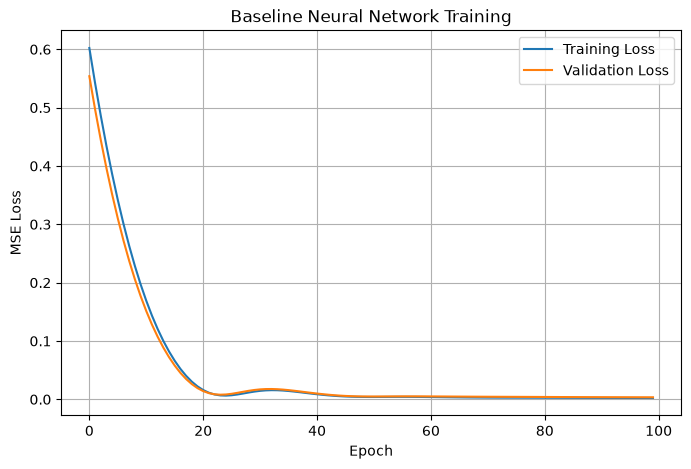

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Baseline Neural Network Training")
plt.legend()
plt.grid(True)
plt.show()